## AIRLINE PASSENGER FORECASTING

## 📌 Project Overview

This project analyzes the classic **Airline Passengers** dataset (Box & Jenkins, 1976) — monthly totals of international airline passengers (in thousands) from **January 1949 to December 1960**. The goal is to:

1. Understand the trend and seasonality in the data through exploratory analysis
2. Transform the series to make it stationary (required for ARIMA-family models)
3. Use `auto_arima` to identify optimal SARIMA hyperparameters
4. Fit a **SARIMAX** model and validate it on a held-out test set
5. Evaluate forecast accuracy using standard error metrics (MAE, RMSE, MAPE)
6. Forecast passenger volume for the next 24 months (1961–1962)

##  Methods Used
- Exploratory Data Analysis (trend/seasonality visual inspection)
- Differencing & log transformation for stationarity
- ACF / PACF analysis
- Seasonal decomposition (trend, seasonality, residuals)
- auto_arima for automated order selection
- SARIMAX modeling (Seasonal ARIMA with eXogenous regressors)
- Train/test split evaluation (sequential — not random, since order matters in time series)
- Model performance metrics MAE, RMSE, MAPE
- Future forecasting (24-month horizon)

In [1]:
# Import All Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# sarima and sarimax
from pmdarima import auto_arima
from statsmodels.tsa.statespace.sarimax import SARIMAX
# mse and mape
from sklearn.metrics import mean_absolute_percentage_error,mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf , plot_pacf
# for Statistical tests
from statsmodels.tsa.stattools import adfuller

In [2]:
# Load dataset
ap=pd.read_csv(r"C:\Users\amoln\Downloads\project_datasets\airline_passengers_pred.csv")
ap.head()

,Month,Thousands of Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [3]:
ap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Month                    144 non-null    object
 1   Thousands of Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [4]:
# check shape
ap.shape

(144, 2)

In [5]:
# Check NULL values
ap.isnull().sum()

Month                      0
Thousands of Passengers    0
dtype: int64

In [6]:
# Data Preparation

In [7]:
# set Month as Index
ap['Month'] = pd.to_datetime(ap['Month'], infer_datetime_format= True )

C:\Users\amoln\AppData\Local\Temp\ipykernel_21948\3040157494.py:2: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  ap['Month'] = pd.to_datetime(ap['Month'], infer_datetime_format= True )


In [8]:
# Set Month as index
ap.set_index('Month', inplace=True)

In [9]:
# Give target variable clean name
ap.rename(columns={'Thousands of Passengers': 'Passengers'}, inplace=True)

In [10]:
ap.head(2)

,Passengers
Month,
1949-01-01,112
1949-02-01,118


In [11]:
# Exploratory Data Analysis (EDA)

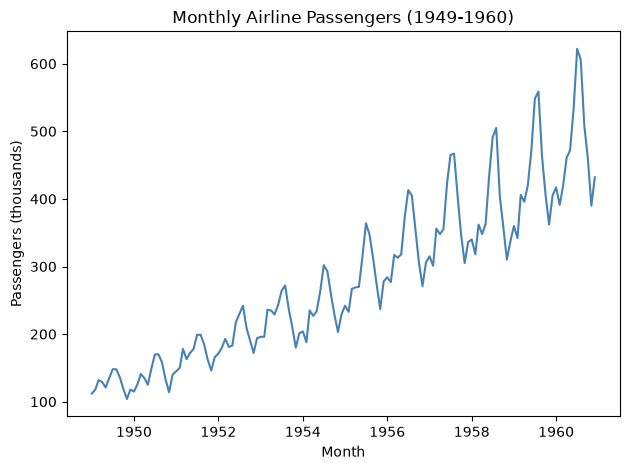

In [12]:
plt.plot(ap.index, ap['Passengers'], color='steelblue')
plt.title('Monthly Airline Passengers (1949-1960)')
plt.xlabel('Month')
plt.ylabel('Passengers (thousands)')
plt.tight_layout()
plt.show()

* The series shows a clear upward trend over time.
* There is a repeating yearly seasonal pattern in every 12 months.
* The raw series is not stationary (mean and variance change over time), which we must address before applying ARIMA-family models.

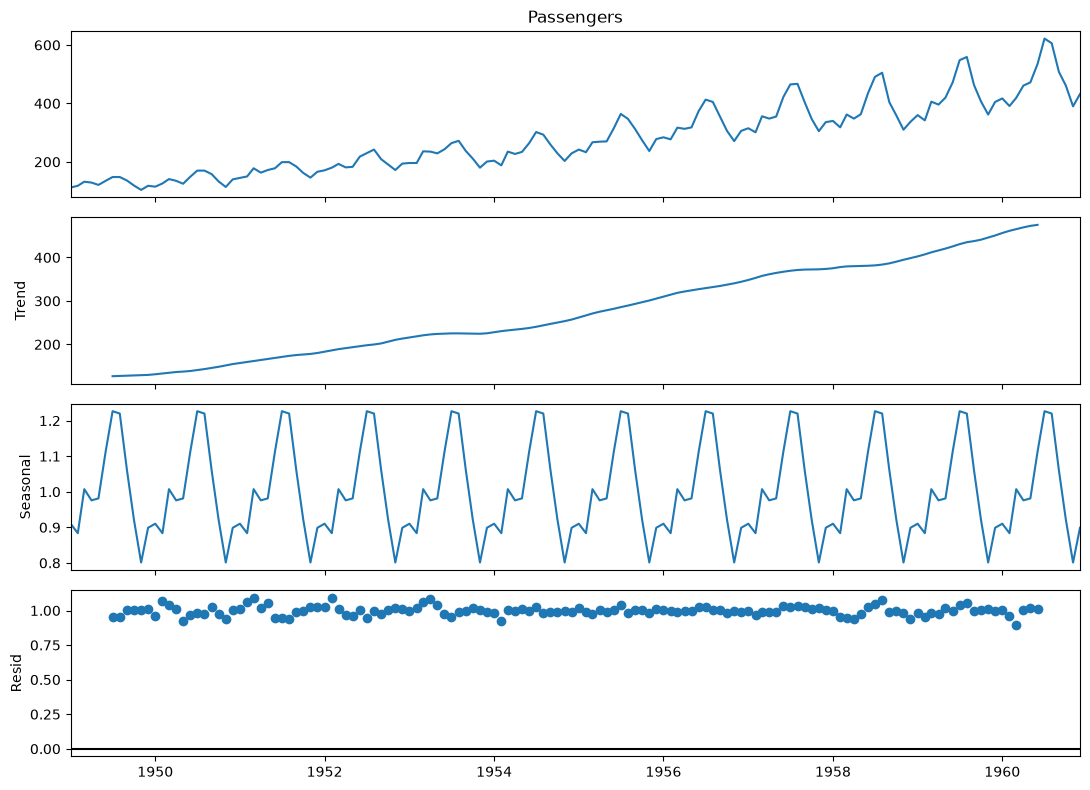

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

#  to find if data is seasonal or not --->
#  and if seasonal then time period of seasonality --->
decomposition = seasonal_decompose(ap['Passengers'], model='multiplicative', period=12)
fig = decomposition.plot()
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

* Trend is consistent long-term growth
* Seasonal: a stable, repeating 12-month cycle

In [ ]:
# Checking Stationary is not Applying Differencing

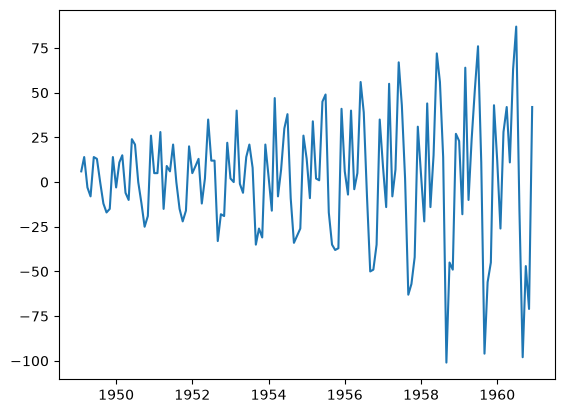

In [14]:
plt.plot(ap['Passengers'].diff()) # level 1 of Differencing 

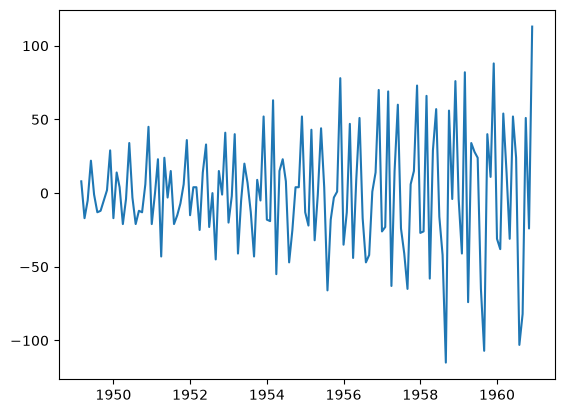

In [15]:
plt.plot(ap['Passengers'].diff().diff()) # Level 2 of Differencing

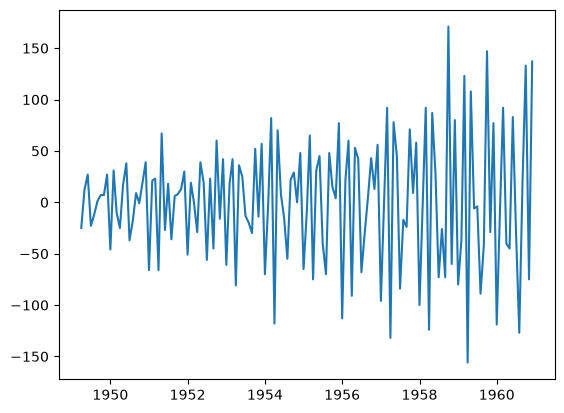

In [16]:
plt.plot(ap['Passengers'].diff().diff().diff()) # Level 3 Of differencing

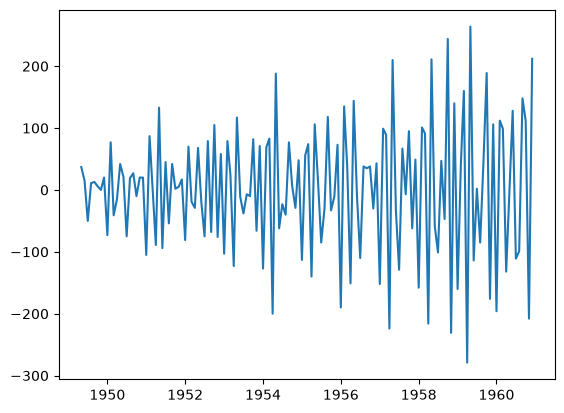

In [17]:
plt.plot(ap['Passengers'].diff().diff().diff().diff()) # level 4 of differencing

# Log Transformation
* log transform stabilizes the variance and converts multiplicative seasonality into an additive pattern that SARIMA handles more naturally.

In [18]:
import numpy as np

In [19]:
log_data = np.log(ap['Passengers'])

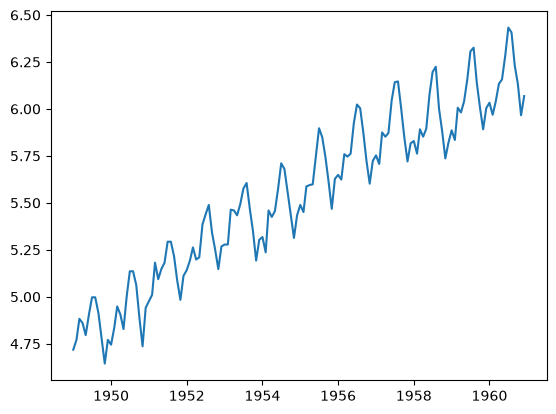

In [20]:
plt.plot(log_data)

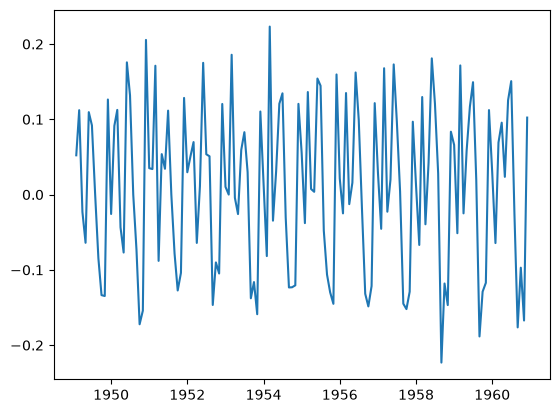

In [21]:
plt.plot(log_data.diff())

* first difference series looks much more stable in variance, with a roughly constant mean 

In [22]:
# ACF and PACF plots

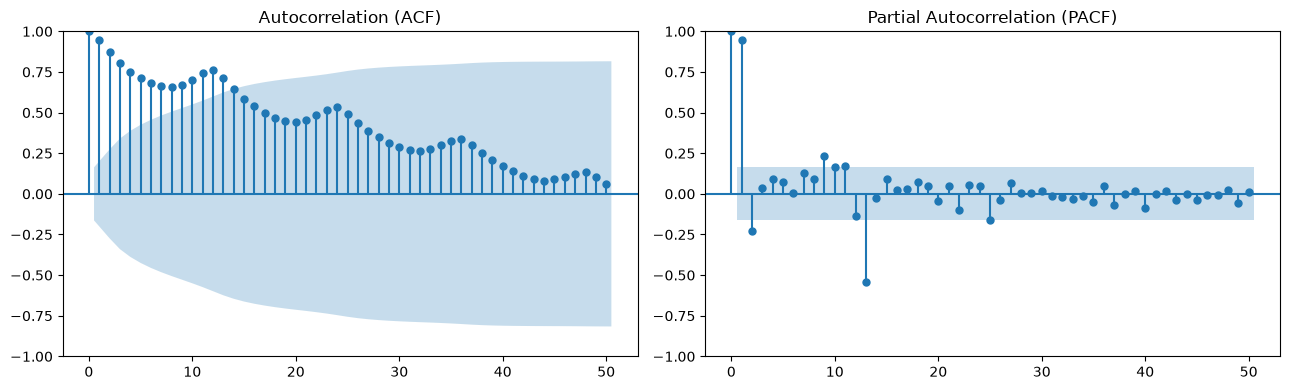

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(ap['Passengers'], lags=50, ax=axes[0])
axes[0].set_title('Autocorrelation (ACF)')
plot_pacf(ap['Passengers'], lags=50, ax=axes[1])
axes[1].set_title('Partial Autocorrelation (PACF)')
plt.tight_layout()
plt.show()

In [24]:
# Model Selection with auto arima

In [25]:
auto_arima(log_data, seasonal=True , m=12)

,order,"(2, ...)"
,seasonal_order,"(0, ...)"
,suppress_warnings,True
,scoring_args,{}
,start_params,None
,method,'lbfgs'
,maxiter,50
,out_of_sample_size,0
,scoring,'mse'
,trend,None
,with_intercept,True


In [26]:
model = auto_arima(log_data, seasonal=True , m=12)
print(model)

 ARIMA(2,0,0)(0,1,1)[12] intercept


In [27]:
model.get_params # we will pass this value in SARIMAX

<bound method BaseEstimator.get_params of ARIMA(order=(2, 0, 0), scoring_args={}, seasonal_order=(0, 1, 1, 12),
      suppress_warnings=True)>

# Train and Test Data
* Time series data cannot be shuffled or randomly sampled
* Train: first 11 years (132 months) → Jan 1949 – Dec 1959
* Test: final 12 months (12 months) → Jan 1960 – Dec 1960

In [29]:
# split data into train and test
train = ap['Passengers'].iloc[:132]
test = ap['Passengers'].iloc[132:]

In [30]:
# check shape of train and test
print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')

Train shape: (132,)
Test shape:  (12,)


* Fit SARIMAX on the training set using the orders identified by auto_arima
* seasonal_order=(0, 1, 1, 12),
* p = 0 , d = 1 , q = 1 , m = 12

In [31]:
import warnings
warnings.filterwarnings('ignore')
model1 = SARIMAX(log_data, order=(2, 0, 0), seasonal_order=(0, 1, 1, 12))
results = model1.fit()

In [32]:
# Forecast on Test Data 

In [33]:
# Number of test values
n_test = len(test)

# Make predictions
forecast = results.get_forecast(steps=n_test)

# Convert predictions back to original scale
test_pred = np.exp(forecast.predicted_mean)
test_pred.index = test.index

# Get 95% confidence interval
conf_int = np.exp(forecast.conf_int())
conf_int.index = test.index

# Show predictions
test_pred.head()

Month
1960-01-01    447.540950
1960-02-01    422.289256
1960-03-01    474.532991
1960-04-01    487.225016
1960-05-01    503.064380
Name: predicted_mean, dtype: float64

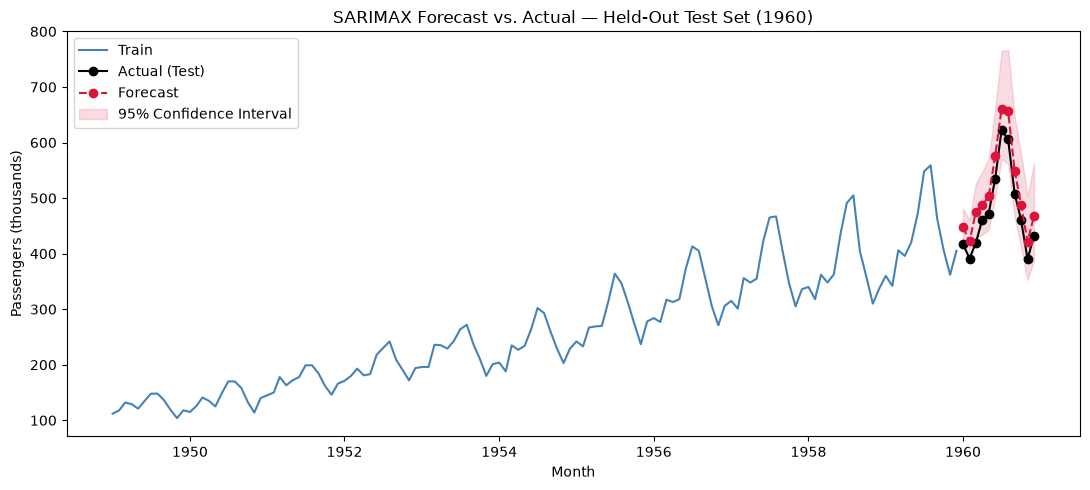

In [34]:
plt.figure(figsize=(11, 5))
plt.plot(train.index, train, label='Train', color='steelblue')
plt.plot(test.index, test, label='Actual (Test)', color='black', marker='o')
plt.plot(test_pred.index, test_pred, label='Forecast', color='crimson', marker='o', linestyle='--')
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                  color='crimson', alpha=0.15, label='95% Confidence Interval')
plt.title('SARIMAX Forecast vs. Actual — Held-Out Test Set (1960)')
plt.xlabel('Month')
plt.ylabel('Passengers (thousands)')
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Model Performance Evaluation

In [36]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , root_mean_squared_error
mae = mean_absolute_error(test, test_pred)
rmse = np.sqrt(mean_squared_error(test, test_pred))
mape = mean_absolute_percentage_error(test, test_pred)

metrics_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE'],
    'Value': [f'{mae:.2f}', f'{rmse:.2f}', f'{mape:.2%}']})
metrics_df

,Metric,Value
0,MAE,36.63
1,RMSE,37.66
2,MAPE,7.77%


In [37]:
results_table = pd.DataFrame({
    'Actual': test,
    'Predicted': test_pred.round(1),})
results_table['Abs. Error'] = (results_table['Actual'] - results_table['Predicted']).abs().round(1)
results_table['% Error'] = (results_table['Abs. Error'] / results_table['Actual'] * 100).round(2)
results_table

,Actual,Predicted,Abs. Error,% Error
Month,,,,
1960-01-01,417,447.5,30.5,7.31
1960-02-01,391,422.3,31.3,8.01
1960-03-01,419,474.5,55.5,13.25
1960-04-01,461,487.2,26.2,5.68
1960-05-01,472,503.1,31.1,6.59
1960-06-01,535,575.7,40.7,7.61
1960-07-01,622,660.4,38.4,6.17
1960-08-01,606,656.7,50.7,8.37
1960-09-01,508,548.8,40.8,8.03


In [38]:
# Create final SARIMAX model
final_model = SARIMAX(log_data, order=(2, 0, 0), seasonal_order=(0, 1, 1, 12))

# Fit the model
final_results = final_model.fit()

In [39]:
# Forecast next 24 months
forecast = final_results.get_forecast(steps=24)

In [40]:
# Create future dates
future_index = pd.date_range(
    start=ap.index[-1] + pd.DateOffset(months=1),
    periods=24,
    freq="MS")

In [41]:
# Convert forecast back to original scale
future_pred = np.exp(forecast.predicted_mean)
future_pred.index = future_index

In [42]:
# Get 95% confidence interval
conf_int = np.exp(forecast.conf_int())
conf_int.index = future_index

In [43]:
# Display future forecast
future_pred.round(1)

1961-01-01    447.5
1961-02-01    422.3
1961-03-01    474.5
1961-04-01    487.2
1961-05-01    503.1
1961-06-01    575.7
1961-07-01    660.4
1961-08-01    656.7
1961-09-01    548.8
1961-10-01    488.2
1961-11-01    421.6
1961-12-01    467.5
1962-01-01    483.8
1962-02-01    456.3
1962-03-01    512.5
1962-04-01    526.0
1962-05-01    542.8
1962-06-01    620.9
1962-07-01    712.0
1962-08-01    707.6
1962-09-01    591.1
1962-10-01    525.6
1962-11-01    453.6
1962-12-01    502.8
Freq: MS, Name: predicted_mean, dtype: float64

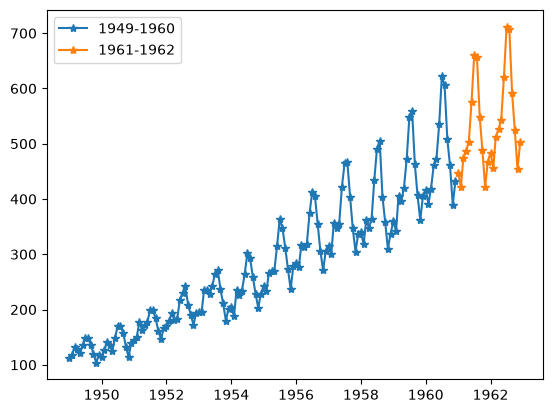

In [44]:
# Plot historical data
plt.plot(ap["Passengers"], marker="*", label="1949-1960")

# Plot next 24 months forecast
plt.plot(future_pred, marker="*", label="1961-1962")

# Show labels
plt.legend()

# Display plot
plt.show()

# Conclusion
* The airline passenger series exhibits a clear upward trend and strong yearly seasonality, with growing seasonal amplitude (multiplicative pattern).
* A log transform + SARIMA(p,d,q)(P,D,Q,12) model — with orders selected via auto_arima — captures both effects well.
* Validated on a held-out 12-month test period, the model achieves a low MAPE, indicating strong short-to-medium term forecasting accuracy.
* Residual diagnostics show no major leftover structure, supporting the model's adequacy.
* The final model forecasts continued growth in passenger volume through 1961–1962, consistent with the historical trend.